# MiniRocket Multivariate
Trasformazione convoluzionale per time series e classificatore Ridge, sui tre canali raw. L'input viene ricostruito da `(N, L*3)` a `(N, 3, L)`. I dati raw sono già zero-padded alla lunghezza configurata; nessun ricampionamento viene applicato. Dipendenza: `sktime`.

In [1]:
import config as cfg, utils, advanced_models as adv
cfg.FORCE_RERUN = True
utils.print_versions()
adv.print_versions()
utils.print_config()
print('kernels:', cfg.QUICK_ROCKET_NUM_KERNELS if cfg.QUICK_TEST else cfg.MINIROCKET_NUM_KERNELS)
MODEL = 'minirocket'

Python      : 3.12.13 | Linux-7.0.0-38-generic-x86_64-with-glibc2.39
numpy       : 2.5.4
pandas      : 3.0.6
scipy       : 1.18.1
sklearn     : 1.9.1
catboost    : 1.2.10
matplotlib  : 3.11.2
natsort     : 8.4.0
tqdm        : 4.70.1
Python: 3.12.13 | Linux-7.0.0-38-generic-x86_64-with-glibc2.39
xgboost: 3.4.1
sktime: 1.2.0
torch: 2.14.1
SEED=89  N_SPLITS=10  CV_MODE=stratified  QUICK_TEST=False
FALL_CLASSES: {'UniMiB': [9, 10, 11, 12, 13, 14, 15, 16], 'UniZgFall': [5, 6, 7]}
kernels: 10000


## Cross-validation, metriche e predizioni

In [2]:
adv.run_all(MODEL)

[minirocket | UniZgFall | raw] X=(468, 3, 5146), classi=10, CV=stratified, fold=10
Parametri: num_kernels=10000, RidgeClassifierCV, seed=89


minirocket|UniZgFall:   0%|          | 0/10 [00:00<?, ?it/s]

[minirocket | UniZgFall | raw | fold 1/10] train su 421 esempi, test su 47
fit in corso...


[minirocket | UniZgFall | raw | fold 1/10] fit 8.14s | predict 0.79s | acc 0.8511 | F1 macro 0.8214
[minirocket | UniZgFall | raw | fold 2/10] train su 421 esempi, test su 47
fit in corso...
[minirocket | UniZgFall | raw | fold 2/10] fit 7.10s | predict 0.81s | acc 0.9362 | F1 macro 0.9086
[minirocket | UniZgFall | raw | fold 3/10] train su 421 esempi, test su 47
fit in corso...
[minirocket | UniZgFall | raw | fold 3/10] fit 7.21s | predict 0.79s | acc 0.8936 | F1 macro 0.8811
[minirocket | UniZgFall | raw | fold 4/10] train su 421 esempi, test su 47
fit in corso...
[minirocket | UniZgFall | raw | fold 4/10] fit 7.05s | predict 0.78s | acc 0.8936 | F1 macro 0.8997
[minirocket | UniZgFall | raw | fold 5/10] train su 421 esempi, test su 47
fit in corso...
[minirocket | UniZgFall | raw | fold 5/10] fit 7.02s | predict 0.78s | acc 0.9149 | F1 macro 0.9093
[minirocket | UniZgFall | raw | fold 6/10] train su 421 esempi, test su 47
fit in corso...
[minirocket | UniZgFall | raw | fold 6/10] fi

minirocket|UniMiB:   0%|          | 0/10 [00:00<?, ?it/s]

[minirocket | UniMiB | raw | fold 1/10] train su 1782 esempi, test su 198
fit in corso...
[minirocket | UniMiB | raw | fold 1/10] fit 11.13s | predict 1.15s | acc 0.6111 | F1 macro 0.6510
[minirocket | UniMiB | raw | fold 2/10] train su 1782 esempi, test su 198
fit in corso...
[minirocket | UniMiB | raw | fold 2/10] fit 11.08s | predict 1.16s | acc 0.5909 | F1 macro 0.6835
[minirocket | UniMiB | raw | fold 3/10] train su 1782 esempi, test su 198
fit in corso...
[minirocket | UniMiB | raw | fold 3/10] fit 11.06s | predict 1.15s | acc 0.5303 | F1 macro 0.5507
[minirocket | UniMiB | raw | fold 4/10] train su 1782 esempi, test su 198
fit in corso...
[minirocket | UniMiB | raw | fold 4/10] fit 11.16s | predict 1.16s | acc 0.5909 | F1 macro 0.6571
[minirocket | UniMiB | raw | fold 5/10] train su 1782 esempi, test su 198
fit in corso...
[minirocket | UniMiB | raw | fold 5/10] fit 10.98s | predict 1.17s | acc 0.6414 | F1 macro 0.6874
[minirocket | UniMiB | raw | fold 6/10] train su 1782 esempi

## Riepilogo

In [3]:
display(adv.summary_table(MODEL))

,dataset,input,accuracy,f1_macro,precision_macro,recall_macro,fit_time,predict_time,fall_sensitivity,fall_specificity,fall_precision
0,UniZgFall,raw,0.9189 ± 0.0343,0.9080 ± 0.0416,0.9305 ± 0.0424,0.9067 ± 0.0415,7.1986 ± 0.3402,0.7849 ± 0.0128,0.9518 ± 0.0694,0.9836 ± 0.0192,0.9470 ± 0.0603
1,UniMiB,raw,0.6035 ± 0.0344,0.6626 ± 0.0440,0.6800 ± 0.0411,0.6657 ± 0.0463,11.0294 ± 0.1403,1.1553 ± 0.0073,0.9986 ± 0.0029,0.9759 ± 0.0232,0.9911 ± 0.0085


## Grafici

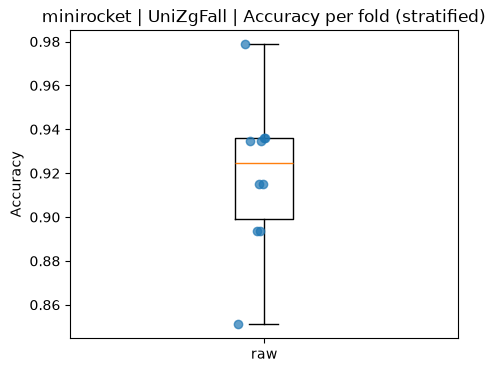

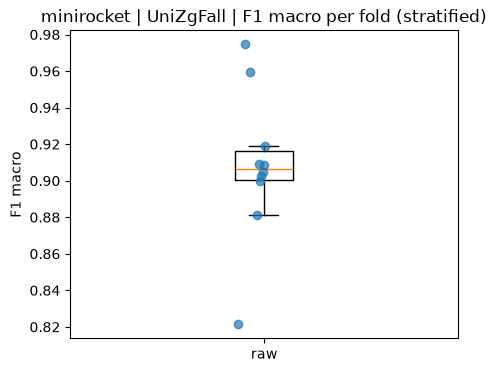

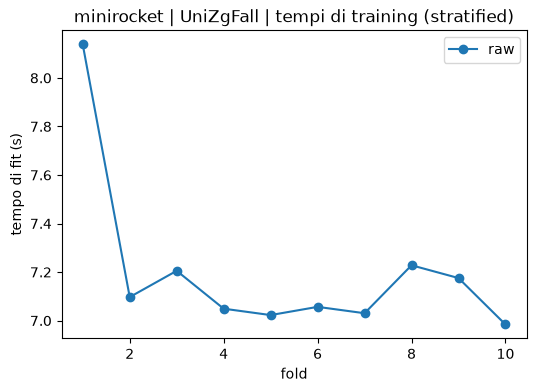

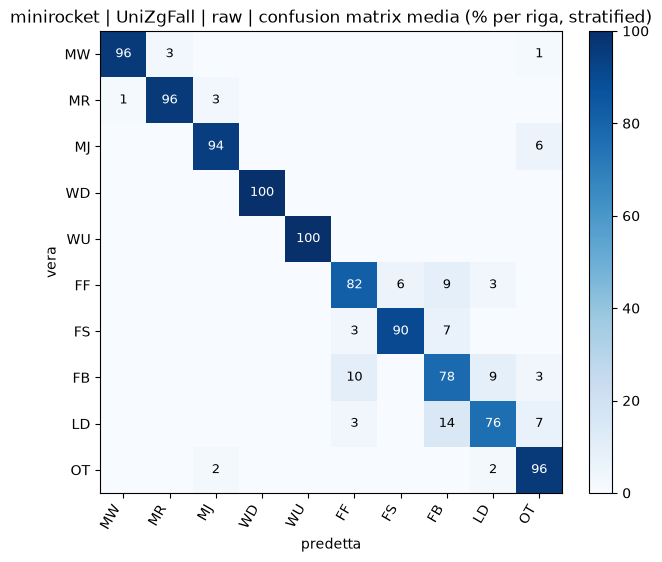

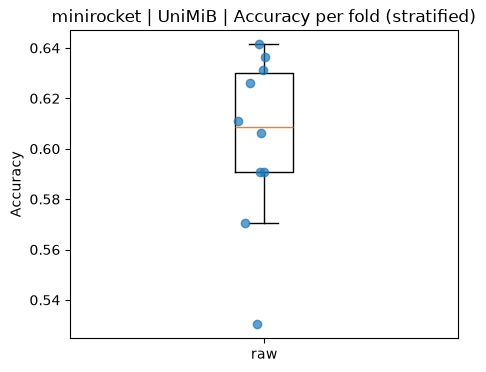

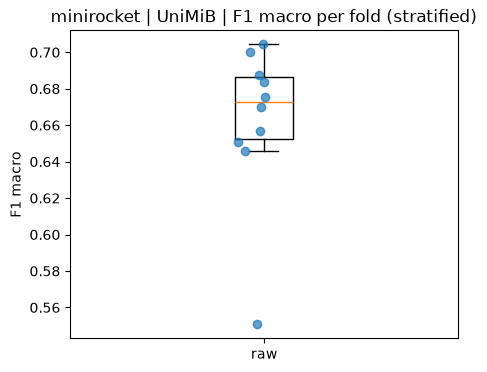

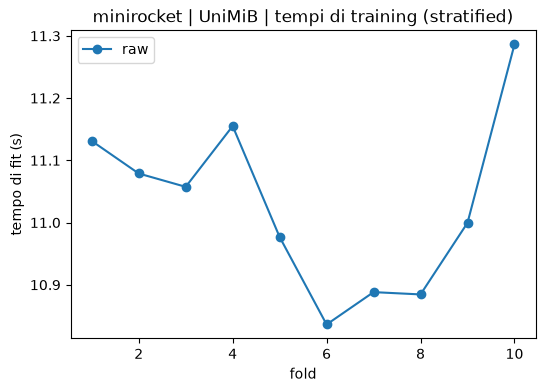

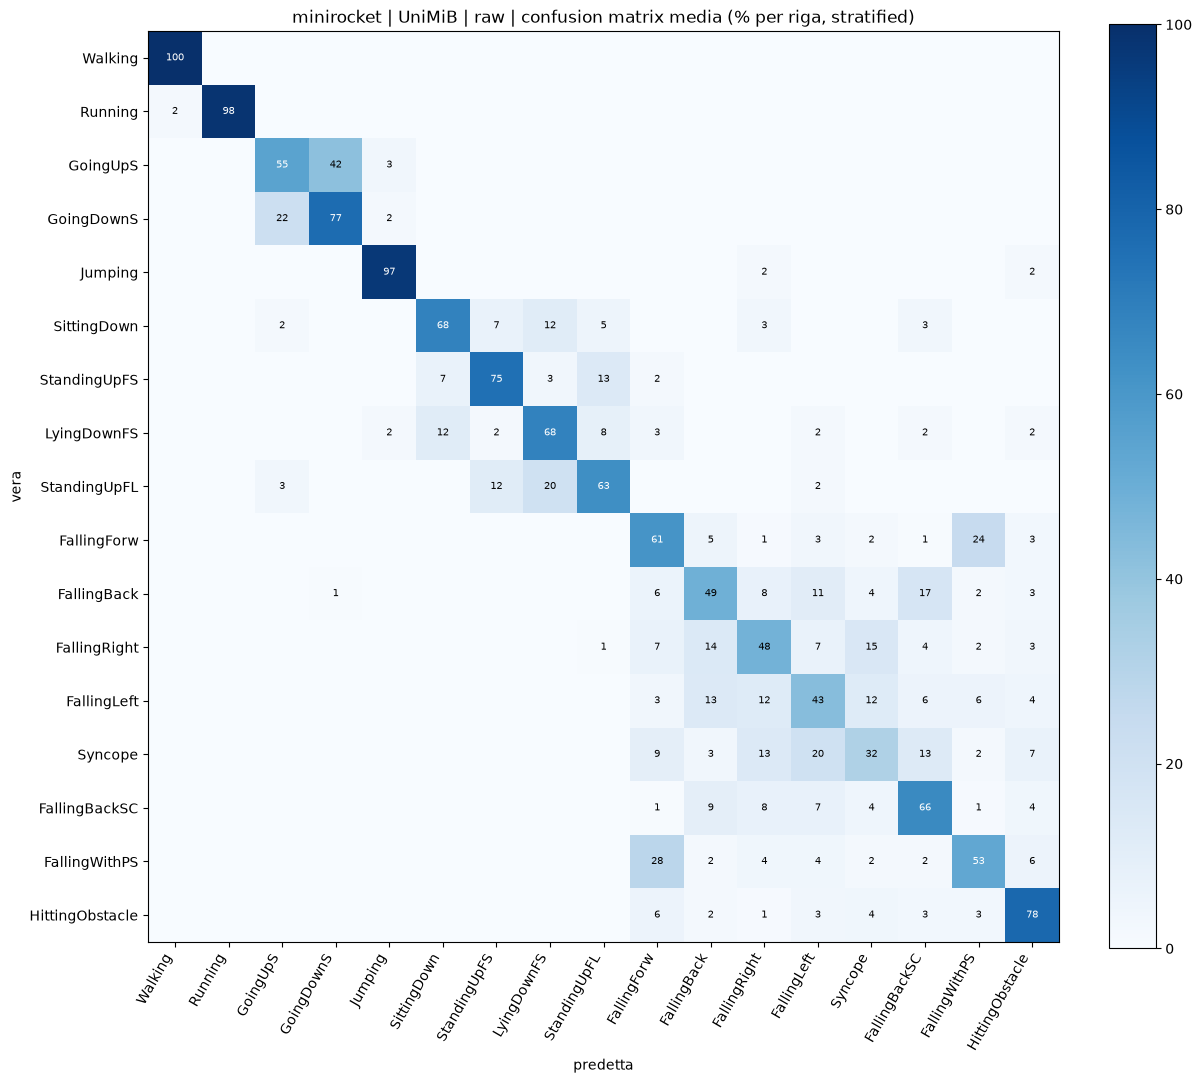

In [4]:
adv.plot_all(MODEL)